In [270]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import convolve2d
from lib.helper_functions import *

In [271]:
file_name = "lib//plate.png"
A_color = Image.open(file_name)
A_g = A_color.convert('L')

In [272]:
# Blurring kernel
K_1 = np.ones([3, 3]) / 9
K = K_1 / K_1.sum()
print(K_1)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [273]:
# Gaussian kernel
K_2 = np.array([[1, 2, 1],
                [2, 5, 2],
                [1, 2, 1]])

K_2 = K_2 / K_2.sum()
print(K_2)

[[0.05882353 0.11764706 0.05882353]
 [0.11764706 0.29411765 0.11764706]
 [0.05882353 0.11764706 0.05882353]]


In [295]:
def convolve(A, K):
    M, N = K.shape
    A = np.pad(A, ((M//2, M//2), (N//2, N//2)), mode='constant', constant_values=0)
    A[1:-1, 1:-1] = np.array([[np.sum(K * A[i-M//2:i+M//2+1, j-N//2:j+N//2+1]) for j in range(1, A.shape[1] - 1)] for i in range(1, A.shape[0] - 1)])
    return A

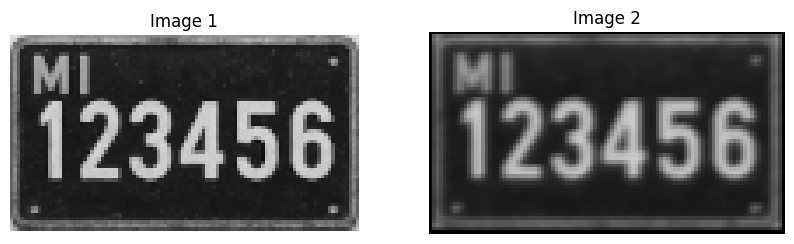

In [294]:
A = np.array(A_g)
R = convolve(A, K_1)
compare_images(A, R)

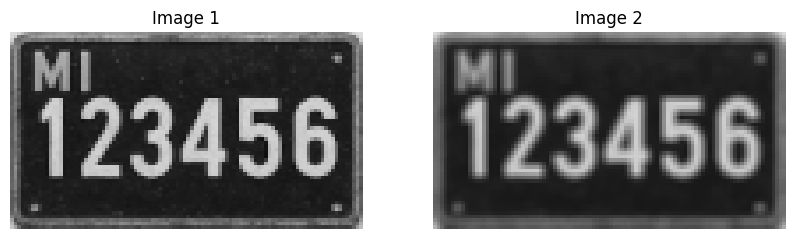

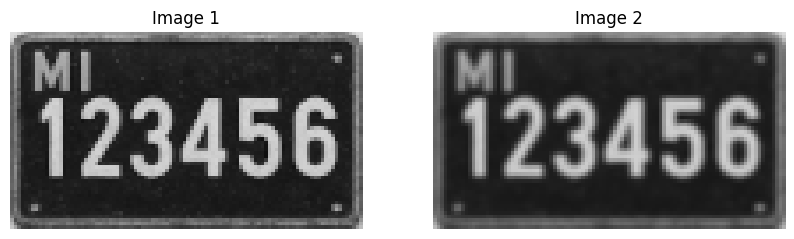

In [ ]:
A = np.array(A_g)
R_1 = convolve2d(A, K_1, mode='same', boundary='symm')
compare_images(A, R_1)
A = np.array(A_g)
R_2 = convolve2d(A, K_2, mode='same', boundary='symm')
compare_images(A, R_2)


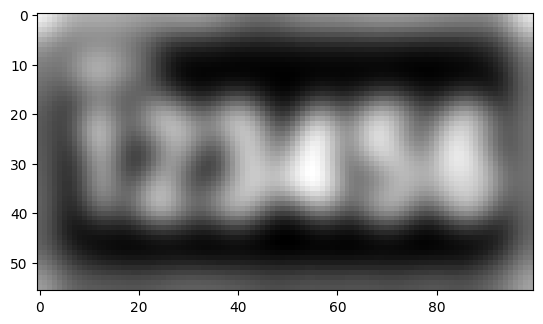

In [275]:
A = np.array(A_g)
N = 20
for i in range(N):
    A = convolve2d(A, K_1, mode='same', boundary='symm')

plt.imshow(A, "gray")

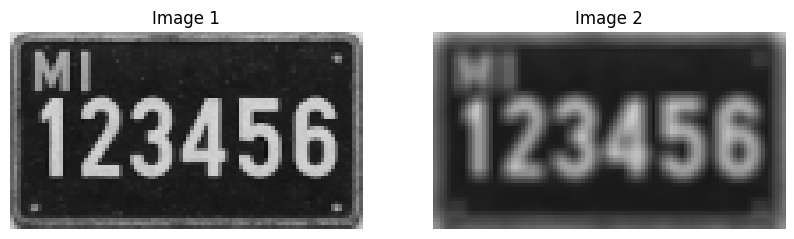

In [276]:
K = np.ones([5, 5]) / 25
A = np.array(A_g)
R = convolve2d(A, K, mode='same', boundary='symm')
compare_images(A, R)

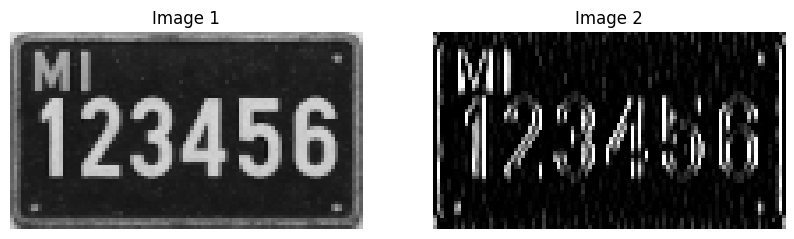

In [277]:
K = np.array([[-1, 2, -1],
              [-1, 2, -1],
              [-1, 2, -1]])

A = np.array(A_g)
R = convolve2d(A, K, mode='same', boundary='symm')
compare_images(A, R)


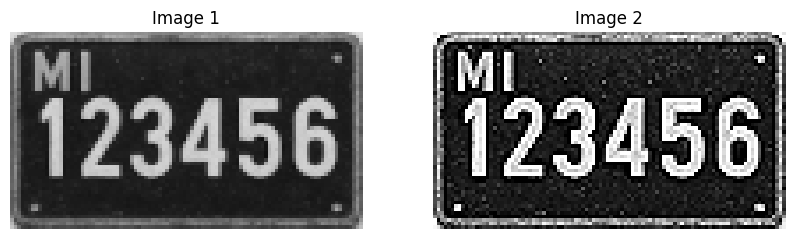

In [278]:
K = np.array([[0, -1, 0],
              [-1, 5, -1],
              [0, -1, 0]])
A = np.array(A_g)
R = convolve2d(A, K, mode='same', boundary='symm')
compare_images(A, R)

In [279]:
file_name = "lib//new.webp"
A_color = Image.open(file_name)

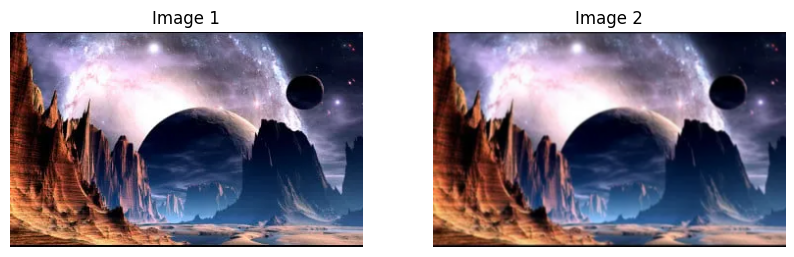

In [283]:
A = np.array(A_color, dtype=float)
kernel = K_2
if A.ndim == 2:
    R = convolve2d(A, kernel, mode='same', boundary='symm')
else:
    channels = [
        convolve2d(A[:, :, c], kernel, mode='same', boundary='symm')
        for c in range(A.shape[2])
    ]
    R = np.stack(channels, axis=2)

R = np.clip(R, 0, 255).astype(np.uint8)
compare_images(np.array(A_color), R)